Loading datasets:
- Train: /kaggle/input/competitions/industrial-machine-condition-classification-mtech/student_dataset.csv
- Test: /kaggle/input/competitions/industrial-machine-condition-classification-mtech/test.csv
- Sample Submission: /kaggle/input/competitions/industrial-machine-condition-classification-mtech/sample_submission.csv

Train shape: (16000, 13)
Test shape:  (4000, 12)
Sub shape:   (4000, 2)

--- Missing Values in Train ---
unit_type          22
ambient_temp       47
process_temp       45
coolant_flow       61
shaft_speed        32
drive_torque       36
power_load         25
component_wear     56
thermal_stress     50
mechanical_load    45
vibration_index    74
dtype: int64

--- Target Distribution ---
condition
0    50.0
1    25.0
2    25.0
Name: proportion, dtype: float64


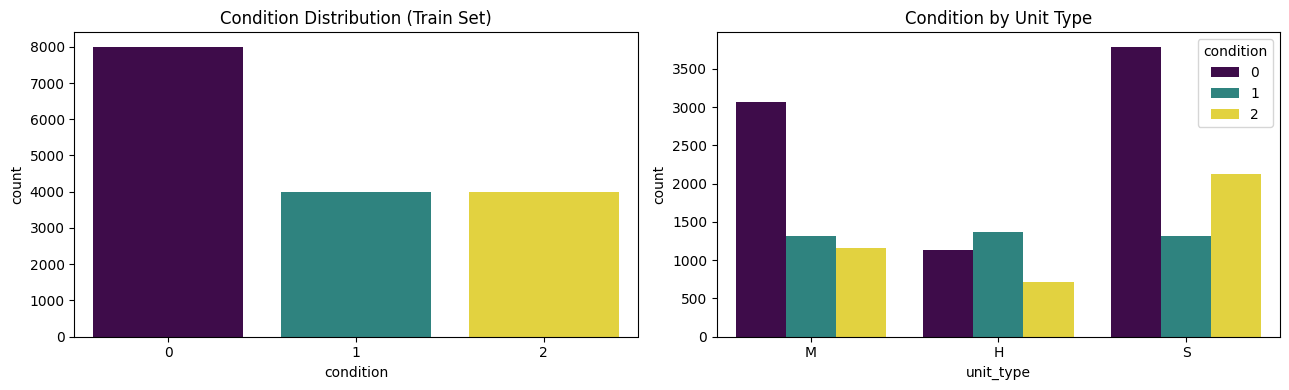


Running 5-Fold Stratified Cross-Validation...
5-Fold Macro F1 Scores: [0.8666 0.8672 0.8671 0.8584 0.8631]
Mean Macro F1 Score:   0.8645 (+/- 0.0034)

Training model on full dataset...

Submission file 'submission.csv' generated successfully!
First 5 rows of submission:
      unit_id  condition
0  UNT-184630          0
1  UNT-228473          0
2  UNT-255783          1
3  UNT-119059          2
4  UNT-205559          0

Predicted Class Distribution in Test Set:
condition
0    2080
1     961
2     959
Name: count, dtype: int64


In [1]:
# ==============================================================================
# Kaggle Notebook: End-to-End Pipeline (EDA, Preprocessing, Random Forest)
# ==============================================================================

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------------------------
# 1. Load Data (Supports root directory and Kaggle /kaggle/input/ paths)
# ------------------------------------------------------------------------------
def find_file(filename):
    for root, _, files in os.walk("."):
        if filename in files:
            return os.path.join(root, filename)
    if os.path.exists("/kaggle/input"):
        for root, _, files in os.walk("/kaggle/input"):
            if filename in files:
                return os.path.join(root, filename)
    return filename

train_path = find_file("student_dataset.csv")
test_path = find_file("test.csv")
sub_path = find_file("sample_submission.csv")

print(f"Loading datasets:\n- Train: {train_path}\n- Test: {test_path}\n- Sample Submission: {sub_path}")

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)
df_sub = pd.read_csv(sub_path)

print(f"\nTrain shape: {df_train.shape}")
print(f"Test shape:  {df_test.shape}")
print(f"Sub shape:   {df_sub.shape}")

# ------------------------------------------------------------------------------
# 2. Exploratory Data Inspection
# ------------------------------------------------------------------------------
target_col = "condition"
id_col = "unit_id"

features = [c for c in df_train.columns if c not in [id_col, target_col]]
num_features = [c for c in features if c != "unit_type"]
cat_features = ["unit_type"]

print("\n--- Missing Values in Train ---")
print(df_train.isnull().sum()[df_train.isnull().sum() > 0])

print("\n--- Target Distribution ---")
print(df_train[target_col].value_counts(normalize=True).round(4) * 100)

# Quick EDA Plot (Warning-free Seaborn syntax)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df_train, x=target_col, hue=target_col, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Condition Distribution (Train Set)")

sns.countplot(data=df_train, x="unit_type", hue=target_col, palette="viridis", ax=axes[1])
axes[1].set_title("Condition by Unit Type")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3. Preprocessing & Model Pipeline
# ------------------------------------------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_features),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            cat_features,
        ),
    ]
)

rf_classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", rf_classifier),
    ]
)

# ------------------------------------------------------------------------------
# 4. Stratified 5-Fold Cross-Validation
# ------------------------------------------------------------------------------
X = df_train[features]
y = df_train[target_col]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("\nRunning 5-Fold Stratified Cross-Validation...")

# Fixed: used 'f1_macro' instead of 'macro'
cv_scores = cross_val_score(model_pipeline, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)

print(f"5-Fold Macro F1 Scores: {np.round(cv_scores, 4)}")
print(f"Mean Macro F1 Score:   {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# ------------------------------------------------------------------------------
# 5. Fit on Full Train Set & Generate Kaggle Submission
# ------------------------------------------------------------------------------
print("\nTraining model on full dataset...")
model_pipeline.fit(X, y)

X_test = df_test[features]
test_predictions = model_pipeline.predict(X_test)

submission = pd.DataFrame({
    id_col: df_test[id_col],
    target_col: test_predictions.astype(int),
})

output_file = "submission.csv"
submission.to_csv(output_file, index=False)

print(f"\nSubmission file '{output_file}' generated successfully!")
print("First 5 rows of submission:")
print(submission.head())
print("\nPredicted Class Distribution in Test Set:")
print(submission[target_col].value_counts())